<a href="https://colab.research.google.com/github/halynazhabchyk/nlp_labs/blob/main/NLP_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

РЕАЛІЗАЦІЯ МОДЕЛІ WORD2VEC ЗА ДОПОМОГОЮ БІБЛІОТЕКИ GENSIM

Мета роботи:  ознайомитися з бібліотекою Gensim. Навчитися створювати та тренувати моделі Word2Vec для отримання ембеддінгів слів. Провести аналіз отриманих ембеддінгів, виконати пошук схожих слів та розв’язати задачі аналогій.


Gensim – це популярна Python-бібліотека для роботи з текстовими
даними та моделей тематичного моделювання. Її головна перевага –
зручність у реалізації та тренуванні моделей для отримання ембеддінгів
слів, таких як Word2Vec, Doc2Vec, FastText та інших.

Для початку здійснимо імпорт бібліотек

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 27.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from gensim.models import Word2Vec
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import re


Наступний крок - завантаження та обробка даних(поділ на тестові та тренувальні дані)

Завантажуємо дані до колабу

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving nyt-ingredients-snapshot-2015.csv to nyt-ingredients-snapshot-2015.csv


In [ ]:
data = pd.read_csv("nyt-ingredients-snapshot-2015.csv", encoding="utf-8")
sentences_all = data['input'].dropna().tolist()

sentences = [re.findall(r'\b\w+\b', sentence.lower()) for sentence in
sentences_all]
len(sentences_all)

179063

Завантажуємо попередньо навчену модель

Для початку перевіряємо список доступних

In [ ]:
import gensim.downloader as api
print(api.info()['models'].keys())

dict_keys(['fasttext-wiki-news-subwords-300', 'conceptnet-numberbatch-17-06-300', 'word2vec-ruscorpora-300', 'word2vec-google-news-300', 'glove-wiki-gigaword-50', 'glove-wiki-gigaword-100', 'glove-wiki-gigaword-200', 'glove-wiki-gigaword-300', 'glove-twitter-25', 'glove-twitter-50', 'glove-twitter-100', 'glove-twitter-200', '__testing_word2vec-matrix-synopsis'])


In [ ]:

# У цьому випадку — word2vec, тренований на корпусі Google News(300-вимірні вектори)
print("Завантажуємо переднавчену модель...")
# print(api.info()['models'].keys())
model = api.load('word2vec-google-news-300')
print("Модель успішно завантажена!")

Завантажуємо переднавчену модель...
[==================================================] 100.0% 1662.8/1662.8MB downloaded
Модель успішно завантажена!


Знайдемо схожі слова до "cheese".
Вирішимо аналогію: "king" : "man" :: "queen" : ?

In [ ]:
# Перевірка: знайти слова, схожі на "cheese"
print("Схожі слова до 'cheese':")
similar_words = model.most_similar("cheese", topn=10)

for word, similarity in similar_words:
 print(f"{word}: {similarity:.4f}")

# Спроба вирішити пропорцію
print("\nПропорція: 'king' : 'man' :: 'queen' : ?")

analogy_result = model.most_similar(positive=["queen", "man"],
negative=["king"], topn=5)

for word, similarity in analogy_result:
 print(f"{word}: {similarity:.4f}")

Схожі слова до 'cheese':
cheeses: 0.7789
cheddar: 0.7628
goat_cheese: 0.7297
Cheese: 0.7287
cheddar_cheese: 0.7255
Cheddar_cheese: 0.6944
mozzarella: 0.6806
cheddar_cheeses: 0.6695
Camembert: 0.6623
gruyere: 0.6615

Пропорція: 'king' : 'man' :: 'queen' : ?
woman: 0.7609
girl: 0.6140
teenage_girl: 0.6041
teenager: 0.5826
lady: 0.5753


Бачимо, що модель коректно виявляє семантичну близькість між словом cheese та назвами його різновидів (cheddar, mozzarella, Camembert, gruyere). У результатах переважають саме види сиру, отже, векторне представлення відображає тематичну та категоріальну близькість.



При перевірці на аналогію, можна побачити, що модель правильно відтворює  семантичну залежність.Відношення king до man інтерпретується як “чоловіча форма монархічної ролі”, тому для queen модель знаходить найближче узагальнене відповідне поняття — woman. Найвища подібність у woman (0.7609) свідчить про те, що векторна різниця king − man + queen дійсно зміщується у напрямку жіночої статі. Наявність girl, lady, teenage_girl демонструє здадтність до узагальнення категорії “жіноча стать”, але не завжди зберігає соціальний або статусний компонент (монархія).



Пошук найбільш схожих слів: для наступних слів знайдемо 5
найближчих слів: "milk", "bread", "butter", "chicken", "coffee".

In [ ]:
selected_words = ["milk", "bread", "butter", "chicken", "coffee"]

for query_word in selected_words:
    print(f"\nСхожі слова до '{query_word}':")
    similar_words = model.most_similar(query_word, topn=10)

    for similar_word, similarity in similar_words:
        print(f"{similar_word}: {similarity:.4f}")




Схожі слова до 'milk':
dairy: 0.7324
cow_milk: 0.6860
milk_powder: 0.6646
camels_Nancy_Riegler: 0.6561
powdered_milk: 0.6498
raw_milk: 0.6309
goat_milk: 0.6261
apple_juice: 0.6173
whey: 0.6159
chocolate_caramel_mousse: 0.6145

Схожі слова до 'bread':
butter: 0.6417
rye_sourdough: 0.6290
breads: 0.6243
loaf: 0.6185
flour: 0.6152
baladi_bread: 0.6061
loaves: 0.6045
raisin_bread: 0.5843
stale_bread: 0.5802
wheaten_flour: 0.5786

Схожі слова до 'butter':
bread: 0.6417
small_saucepan_melt: 0.6312
melted_butter: 0.6044
unsalted_butter: 0.6009
large_skillet_melt: 0.5963
Lightly_toast: 0.5925
Saute_mushrooms: 0.5913
medium_saucepan_melt: 0.5912
melted_margarine: 0.5883
heavy_saucepan_melt: 0.5879

Схожі слова до 'chicken':
meat: 0.6799
Chicken: 0.6726
chickens: 0.6598
poultry: 0.6559
pork: 0.6542
grilled_herbed: 0.6516
pasta_fazool: 0.6511
boneless_chicken: 0.6347
turkey: 0.6283
rotisserie_roasted: 0.6276

Схожі слова до 'coffee':
coffees: 0.7213
gourmet_coffee: 0.7057
Coffee: 0.6900
o_joe: 0

Модель визначила як найближчі до слова milk такі слова, як dairy, cow_milk, milk_powder тощо. Більшість із них безпосередньо пов’язані з молочними продуктами або є їх різновидами. Наявність слова apple_juice пояснюється тим, що обидва слова часто вживаються в подібному контексті як напої.
Для слова bread модель повернула  поєднання різновидів хліба, форм слова (множина) та інгредієнтів, пов’язаних із випічкою. Особливо показовим є зв’язок bread і butter, оскільки ці слова часто співвживаються, що відображає асоціативну семантичну близькість.
У випадку butter найближчими виявилися bread, melted_butter, unsalted_butter, melted_margarine. Отже, модель враховує не лише категоріальну подібність, а й контекст приготування їжі. Тобто векторне представлення формується на основі статистики спільної появи слів у текстах.
Для chicken модель визначила продукти, для яких чітко простежується семантичний кластер м’ясних продуктів і птиці. Аналогічно, для coffee найближчими стали coffees, gourmet_coffee, coffee_beans, espresso, cappuccino, latté, що відображає групування різновидів кави та пов’язаних понять.
Загалом результати відображають  як категоріальну близькість (різновиди продукту), так і асоціативну (часте спільне вживання). Це підтверджує, що векторні представлення слів коректно кодують статистичну структуру корпусу та відображають реальні мовні зв’язки.


Розв’язання семантичних пропорцій. Використовуючи модель,
вирішимо наступні пропорції:
"Paris" : "France" :: "Berlin" : ?
"big" : "bigger" :: "small" : ?
"cat" : "kitten" :: "dog" : ?

In [ ]:
# Спроба вирішити пропорцію
print("\nПропорція: 'Paris' : 'France' :: 'Berlin' : ?")

analogy_result = model.most_similar(
    positive=["France", "Berlin"],
    negative=["Paris"],
    topn=5
)

for word, similarity in analogy_result:
    print(f"{word}: {similarity:.4f}")


Пропорція: 'Paris' : 'France' :: 'Berlin' : ?
Germany: 0.7901
Austria: 0.6027
German: 0.6005
Germans: 0.5851
Poland: 0.5847


In [ ]:
print("\nПропорція: 'big' : 'bigger' :: 'small' : ?")

analogy_result = model.most_similar(
    positive=["bigger", "small"],
    negative=["big"],
    topn=5
)

for word, similarity in analogy_result:
    print(f"{word}: {similarity:.4f}")


Пропорція: 'big' : 'bigger' :: 'small' : ?
larger: 0.7402
smaller: 0.7330
tiny: 0.5698
tinier: 0.5440
large: 0.5192


In [ ]:
print("\nПропорція: 'cat' : 'kitten' :: 'dog' : ?")

analogy_result = model.most_similar(
    positive=["kitten", "dog"],
    negative=["cat"],
    topn=5
)

for word, similarity in analogy_result:
    print(f"{word}: {similarity:.4f}")


Пропорція: 'cat' : 'kitten' :: 'dog' : ?
puppy: 0.7700
pup: 0.6862
pit_bull: 0.6777
dogs: 0.6771
Rottweiler: 0.6647


Бачимо, що модель коректно відтворює семантичні відношення між словами. У пропорції "Paris" : "France" :: "Berlin" : ? вона визначила Germany як найбільш імовірну відповідь (0.7901), оскільки зв’язок повинен бути «столиця — країна».

У прикладі "big" : "bigger" :: "small" : ? модель фактично вловлює ступені порівняння прикметників: серед варіантів є smaller (0.7330).

У пропорції "cat" : "kitten" :: "dog" : ? модель правильно знаходить puppy (0.7700), тобто зберігає відношення «тварина — її дитинча».

Для візуалізації ембеддінгів використаємо метод t-SNE  

In [ ]:

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

selected_words_v = ["cheese", "milk", "bread", "butter",
                    "cake", "chicken", "fish", "wine"]

def visualize_embeddings(selected_words, model):
    # Отримуємо вектори
    words = [word for word in selected_words if word in model]
    embeddings = np.array([model[word] for word in words])

    # Зниження розмірності
    tsne = TSNE(n_components=2,perplexity=min(5, len(words)-1), random_state=42, init="random")
    reduced_embeddings = tsne.fit_transform(embeddings)

    # Візуалізація
    plt.figure(figsize=(10, 7))
    for idx, word in enumerate(words):
        x, y = reduced_embeddings[idx]
        plt.scatter(x, y)
        plt.annotate(word, (x, y), fontsize=10, alpha=0.7)

    plt.title("Візуалізація ембеддінгів (t-SNE)")
    plt.show()


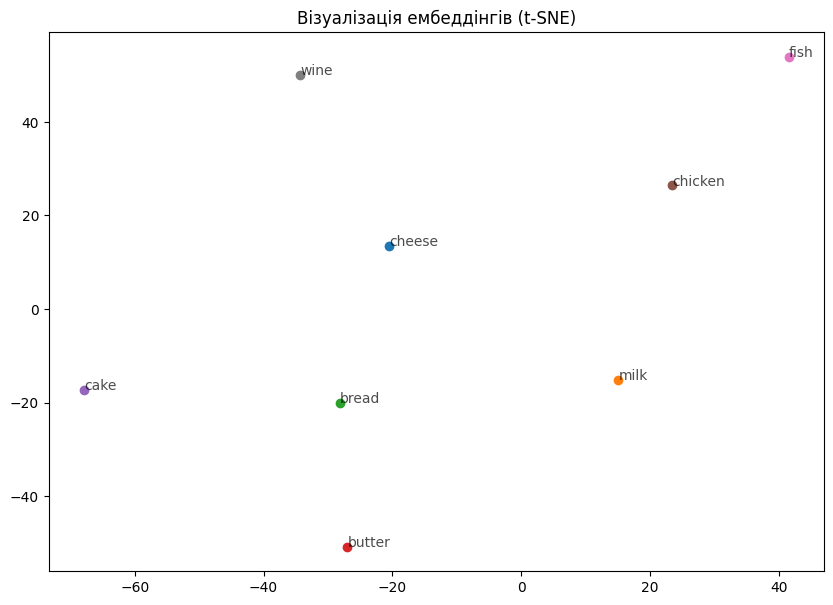

In [ ]:
# Виклик функції для візуалізації
visualize_embeddings(selected_words_v, model)

Можемо побачити, що слова, які мають близьку семантичну подібність зназодяться ближче у просторі ембенденгів.

Проте, для покращення візуалізації кластерів нам необхідно збільшити кількість слів (20–50), щоб чіткіше побачити структуру, додати більше тематичних груп для порівняння (наприклад, країни, прикметники) та використати кольори для різних тематичних груп.

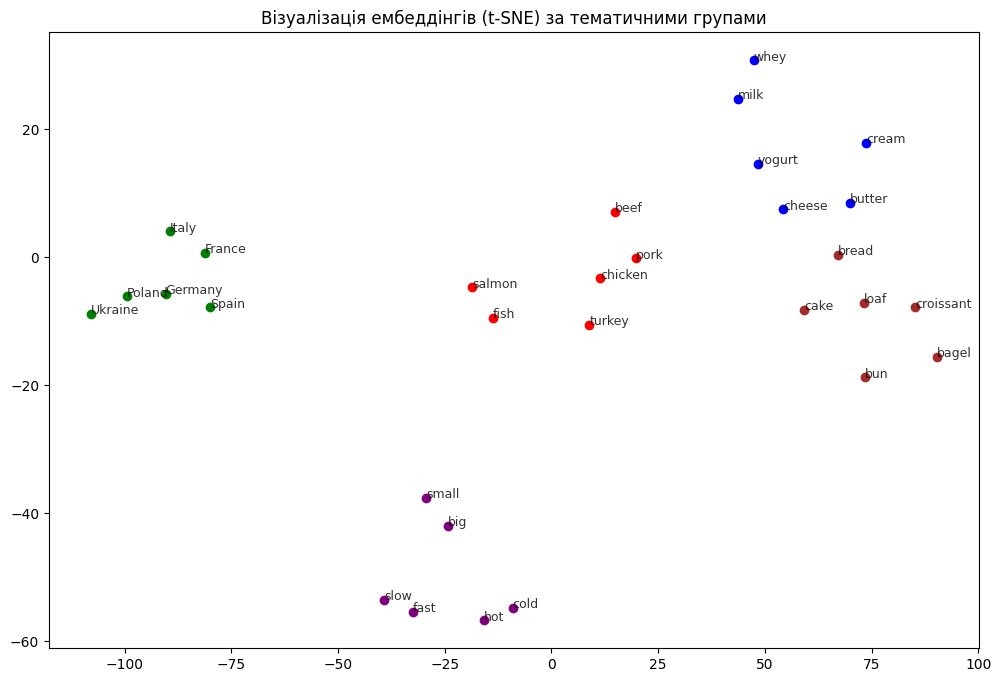

In [ ]:


groups = {
    "Dairy": {
        "words": ["milk", "cheese", "butter", "yogurt", "cream", "whey"],
        "color": "blue"
    },
    "Bakery": {
        "words": ["bread", "cake", "bun", "croissant", "loaf", "bagel"],
        "color": "brown"
    },
    "Meat/Fish": {
        "words": ["chicken", "beef", "pork", "fish", "salmon", "turkey"],
        "color": "red"
    },
    "Countries": {
        "words": ["France", "Germany", "Italy", "Spain", "Poland", "Ukraine"],
        "color": "green"
    },
    "Adjectives": {
        "words": ["big", "small", "hot", "cold", "fast", "slow"],
        "color": "purple"
    }
}

def visualize_embeddings(groups, model):
    words = []
    colors = []

    # Збір слів і кольорів
    for group in groups.values():
        for word in group["words"]:
            if word in model:
                words.append(word)
                colors.append(group["color"])

    embeddings = np.array([model[word] for word in words])


    tsne = TSNE(
        n_components=2,
        perplexity=min(5, len(words)-1),
        random_state=42,
        init="random"
    )
    reduced_embeddings = tsne.fit_transform(embeddings)

    # Візуалізація
    plt.figure(figsize=(12, 8))

    for idx, word in enumerate(words):
        x, y = reduced_embeddings[idx]
        plt.scatter(x, y, color=colors[idx])
        plt.annotate(word, (x, y), fontsize=9, alpha=0.8)

    plt.title("Візуалізація ембеддінгів (t-SNE) за тематичними групами")
    plt.show()

# Виклик
visualize_embeddings(groups, model)

Тепер ми бачимо що схожі за семантикою слова утворють чіткі, спостережувані кластери і знаходяться ближче по векторних відстаннях.

Далі перевіримо, чи слова, які є синонімами, близькі у
просторі ембеддінгів: "big", "large", "huge", "enormous".

In [ ]:
synonyms = ["big", "large", "huge", "enormous"]

for i in range(len(synonyms)):
    for j in range(i+1, len(synonyms)):
        w1, w2 = synonyms[i], synonyms[j]
        if w1 in model.key_to_index and w2 in model.key_to_index:
            vec1 = model.get_vector(w1)
            vec2 = model.get_vector(w2)
            similarity = np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))
            print(f"Схожість '{w1}' – '{w2}': {similarity:.4f}")
        else:
            print(f"Одне зі слів '{w1}' або '{w2}' відсутнє у словнику.")

Схожість 'big' – 'large': 0.5561
Схожість 'big' – 'huge': 0.7810
Схожість 'big' – 'enormous': 0.4655
Схожість 'large' – 'huge': 0.6589
Схожість 'large' – 'enormous': 0.5597
Схожість 'huge' – 'enormous': 0.7833


Модель демонструє, що синоніми, такі як big, large, huge та enormous, розташовані близько один до одного у векторному просторі. Значення схожості підтверджують, що слова з подібним значенням мають тісні семантичні зв’язки. Загалом результати відповідають очікуванням і показують, що ембеддинги ефективно відтворюють відношення синонімів у текстових даних.